# Orbits around black holes

A playground for geodesics with `grsim`. Pick a spacetime, set up a starting
position and velocity, integrate with RK4, and look at the orbit, its radius over
time, the effective potential and how well the conserved quantities are kept.

**How to use it:** run the first three cells once (imports, setup helpers, plotting).
Then run any of the examples, or go to **Other Orbits** at the bottom and change
the numbers.

Units: $G = c = M = 1$, so distances are in units of the mass $M$.
Signature $(-,+,+,+)$, coordinates $(t, r, \theta, \phi)$, state
$y = (t, r, \theta, \phi,\; u^t, u^r, u^\theta, u^\phi)$.

Useful radii in Schwarzschild: horizon $r = 2M$, photon sphere $r = 3M$,
innermost stable circular orbit (ISCO) $r = 6M$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from grsim import Schwarzschild, Kerr
from grsim.integrator import integrate, geodesic_rhs
from grsim.diagnostics import conserved_quantities, max_relative_drift

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#b5b4ad",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2,
    "legend.frameon": False,
})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # series colors, always in this order
GRAY, INK = "#8a897f", "#2b2a27"                        # reference lines and text

## Setting up a starting state

All helpers return a state `y0` of length 8. You only choose the position and the
spatial velocity; $u^t$ is always solved from the normalization
$g_{\mu\nu} u^\mu u^\nu = \kappa$ ($\kappa = -1$ for a massive particle, $0$ for light),
so the state is physically valid.

| Helper | What you give | Spacetime |
|---|---|---|
| `initial_state(metric, r0, theta0, phi0, ur, utheta, uphi, kappa)` | position and $u^r, u^\theta, u^\phi$ | any |
| `circular_orbit(metric, r)` | radius ($r > 3M$; stable only for $r > 6M$) | Schwarzschild |
| `bound_orbit(metric, r_peri, r_apo)` | closest and farthest distance | Schwarzschild |
| `orbit_from_E_L(metric, E, L)` | energy and angular momentum (starts at apoapsis) | Schwarzschild |
| `photon(metric, b, r0)` | impact parameter $b = L/E$ of a light ray coming in from $r_0$ | Schwarzschild |

In [2]:
def horizon(metric):
    # Radius of the (outer) event horizon, or 0 if there is none.
    if isinstance(metric, Kerr):
        M, a = metric.param_values
        return M + np.sqrt(M**2 - a**2)
    if isinstance(metric, Schwarzschild):
        return 2 * metric.param_values[0]
    return 0.0


def initial_state(metric, r0, theta0=np.pi / 2, phi0=0.0, ur=0.0, utheta=0.0, uphi=0.0, kappa=-1):
    # Starting state at (t=0, r0, theta0, phi0) with the given u^r, u^theta, u^phi.
    # u^t > 0 is solved from g_tt ut^2 + 2 g_tphi ut uphi + (spatial part) = kappa,
    # which also works for Kerr with its g_tphi term.
    x = np.array([0.0, r0, theta0, phi0])
    g = metric.g(x)
    A = g[0, 0]
    B = 2 * g[0, 3] * uphi
    C = g[1, 1] * ur**2 + g[2, 2] * utheta**2 + g[3, 3] * uphi**2 - kappa
    disc = B**2 - 4 * A * C
    if disc < 0:
        raise ValueError("No valid u^t: this velocity is faster than light here.")
    ut = (-B - np.sqrt(disc)) / (2 * A)
    return np.array([*x, ut, ur, utheta, uphi])


def circular_orbit(metric, r):
    # Schwarzschild circular orbit at radius r (needs r > 3M; stable only for r > 6M).
    M = metric.param_values[0]
    return initial_state(metric, r, uphi=np.sqrt(M / r**3) / np.sqrt(1 - 3 * M / r))


def turning_points(E, L, M=1.0, kappa=-1):
    # Radii where u^r = 0: roots of E^2 = (1 - 2M/r)(-kappa + L^2/r^2).
    roots = np.roots([E**2 + kappa, 2 * M * (-kappa), -L**2, 2 * M * L**2])
    return np.sort(roots[np.abs(roots.imag) < 1e-9].real)


def orbit_from_E_L(metric, E, L):
    # Schwarzschild bound orbit with energy E < 1 and angular momentum L, started at apoapsis.
    M = metric.param_values[0]
    r = turning_points(E, L, M)
    if len(r) < 3 or r[-1] <= 2 * M:
        raise ValueError("These E, L do not give a bound orbit outside the horizon.")
    return initial_state(metric, r[-1], uphi=L / r[-1]**2)


def bound_orbit(metric, r_peri, r_apo):
    # Schwarzschild bound orbit swinging between r_peri and r_apo, started at apoapsis.
    M = metric.param_values[0]
    f1, f2 = 1 - 2 * M / r_peri, 1 - 2 * M / r_apo
    L2 = (f2 - f1) / (f1 / r_peri**2 - f2 / r_apo**2)
    E = np.sqrt(f1 * (1 + L2 / r_peri**2))
    if L2 <= 0 or turning_points(E, np.sqrt(L2), M)[0] >= r_peri - 1e-9:
        raise ValueError("No stable orbit with this periapsis: the particle would plunge.")
    return initial_state(metric, r_apo, uphi=np.sqrt(L2) / r_apo**2)


def photon(metric, b, r0=30.0):
    # Schwarzschild light ray at r0 moving inward with impact parameter b = L/E (E = 1).
    M = metric.param_values[0]
    f = 1 - 2 * M / r0
    ur = -np.sqrt(1 - f * b**2 / r0**2)
    return initial_state(metric, r0, ur=ur, uphi=b / r0**2, kappa=0)

## Running and plotting

`run` integrates and stops just before the horizon: in Schwarzschild/Boyer-Lindquist
coordinates $u^t \to \infty$ there and the numbers blow up, even though nothing
physical happens to the particle.

`plot_orbit` shows four panels:
1. the orbit seen from above (projected onto the equatorial plane), with the horizon in black;
2. the radius $r$ against proper time $\tau$;
3. the effective potential $V_\text{eff}(r)$ with the particle's $E^2$ (Schwarzschild, equatorial orbits);
4. how much $g(u,u)$, $E$ and $L_z$ drift: a measure of the numerical error.

In [3]:
def run(metric, y0, tau_end, h=0.5, verbose=True):
    # Integrates from tau = 0 to tau_end with step h; stops just before the horizon.
    with np.errstate(all="ignore"):
        taus, ys = integrate(geodesic_rhs, y0, 0.0, tau_end, h, metric)
    r_h = horizon(metric)
    bad = ~np.isfinite(ys).all(axis=1) | (ys[:, 1] < 1.05 * r_h) | (np.abs(ys[:, 4]) > 1e4)
    if bad.any():
        n = int(np.argmax(bad))
        if verbose:
            print(f"Stopped at tau = {taus[n - 1]:.1f}: the particle reached the horizon (r = {r_h:.2f}).")
        taus, ys = taus[:n], ys[:n]
    elif verbose:
        print(f"Integrated {len(ys) - 1} steps up to tau = {tau_end}.")
    return taus, ys


def cartesian(metric, ys):
    # x, y, z for plotting (for Kerr with the Boyer-Lindquist radius sqrt(r^2 + a^2)).
    r, th, ph = ys[:, 1], ys[:, 2], ys[:, 3]
    a = metric.param_values[1] if isinstance(metric, Kerr) else 0.0
    rho = np.sqrt(r**2 + a**2) * np.sin(th)
    return rho * np.cos(ph), rho * np.sin(ph), r * np.cos(th)


def draw_black_hole(ax, metric, labels=True):
    ax.add_patch(plt.Circle((0, 0), horizon(metric), color=INK, zorder=3))
    if isinstance(metric, Schwarzschild):
        M = metric.param_values[0]
        for radius, name in ((3 * M, "photon sphere"), (6 * M, "ISCO")):
            ax.add_patch(plt.Circle((0, 0), radius, fill=False, ls="--", lw=1, color=GRAY))
            if labels:
                ax.annotate(name, (0, radius), xytext=(0, 2), textcoords="offset points",
                            ha="center", va="bottom", fontsize=8, color=GRAY)


def periapsis_advance(ys):
    # Extra angle (radians) gained between consecutive periapses, beyond one full turn.
    r = ys[:, 1]
    i = np.where((r[1:-1] < r[:-2]) & (r[1:-1] <= r[2:]))[0] + 1
    return np.diff(ys[i, 3]) - 2 * np.pi


def plot_orbit(metric, taus, ys, kappa=-1, title=""):
    norm, E, L = conserved_quantities(metric, ys)
    x, y, _ = cartesian(metric, ys)
    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    (ax_orbit, ax_r), (ax_v, ax_drift) = axes
    fig.suptitle(title, fontsize=13, color=INK)

    # 1. orbit from above
    ax_orbit.plot(x, y, color=BLUE, lw=1.2)
    ax_orbit.plot(x[0], y[0], "o", ms=8, color=BLUE, mec="white", mew=2, zorder=4, label="start")
    reach = 1.1 * np.max(np.abs(np.r_[x, y, 6.5]))
    draw_black_hole(ax_orbit, metric, labels=reach < 25)
    ax_orbit.set(xlim=(-reach, reach), ylim=(-reach, reach), aspect="equal",
                 xlabel="x / M", ylabel="y / M", title="Orbit (seen from above)")
    ax_orbit.legend(loc="upper right")

    # 2. radius against proper time
    ax_r.plot(taus, ys[:, 1], color=BLUE)
    ax_r.axhline(horizon(metric), color=INK, lw=1)
    ax_r.annotate("horizon", (taus[-1], horizon(metric)), xytext=(-4, 3), textcoords="offset points",
                  ha="right", va="bottom", fontsize=8, color=INK)
    ax_r.set(xlabel="proper time τ / M" if kappa else "affine parameter λ", ylabel="r / M",
             title="Radius over time", ylim=(0, None))

    # 3. effective potential (Schwarzschild, orbit in the equatorial plane)
    if isinstance(metric, Schwarzschild) and np.allclose(ys[:, 2], np.pi / 2):
        M = metric.param_values[0]
        rr = np.linspace(2.05 * M, 1.4 * ys[:, 1].max(), 800)
        V = (1 - 2 * M / rr) * (-kappa + L[0]**2 / rr**2)
        ax_v.plot(rr, V, color=BLUE, label=r"$V_\mathrm{eff}(r)$")
        ax_v.axhline(E[0]**2, color=ORANGE, ls="--", lw=1.5, label=r"$E^2$")
        ax_v.axvspan(ys[:, 1].min(), ys[:, 1].max(), color=ORANGE, alpha=0.08, lw=0)
        r_orbit = ys[:, 1]
        V_orbit = (1 - 2 * M / r_orbit) * (-kappa + L[0]**2 / r_orbit**2)
        lo = min(V_orbit.min(), E[0]**2)
        hi = max(V[rr > 3 * M].max(), E[0]**2)
        pad = 0.15 * (hi - lo) + 1e-6
        ax_v.set(xlabel="r / M", ylabel=r"$V_\mathrm{eff}$", ylim=(lo - pad, hi + pad),
                 title=f"Effective potential (L = {L[0]:.3f})")
        ax_v.legend(loc="best")
    else:
        ax_v.axis("off")
        ax_v.text(0.5, 0.5, "Effective potential shown for\nequatorial Schwarzschild orbits only",
                  ha="center", va="center", color=GRAY, transform=ax_v.transAxes)

    # 4. drift of the conserved quantities
    floor = 1e-17
    ax_drift.semilogy(taus, np.abs(norm - kappa) + floor, color=BLUE, label=r"$|g(u,u) - \kappa|$")
    ax_drift.semilogy(taus, np.abs(E / E[0] - 1) + floor, color=ORANGE, label=r"$|E/E_0 - 1|$")
    ax_drift.semilogy(taus, np.abs(L / L[0] - 1) + floor, color=AQUA, label=r"$|L/L_0 - 1|$")
    ax_drift.set(xlabel=ax_r.get_xlabel(), ylabel="drift", title="Numerical error (conserved quantities)",
                 ylim=(floor, None))
    ax_drift.legend(loc="lower right")
    if max(np.max(np.abs(norm - kappa)), max_relative_drift(E), max_relative_drift(L)) == 0:
        ax_drift.set_ylim(floor, 1e-12)
        ax_drift.text(0.5, 0.6, "no drift at all: exactly conserved", ha="center", color=GRAY,
                      transform=ax_drift.transAxes)

    fig.tight_layout()
    plt.show()
    print(f"E = {E[0]:.6f},  L = {L[0]:.6f},  r between {ys[:, 1].min():.3f} and {ys[:, 1].max():.3f}")
    print(f"max drift:  |g(u,u) - κ| = {np.max(np.abs(norm - kappa)):.1e},  "
          f"E = {max_relative_drift(E):.1e},  L = {max_relative_drift(L):.1e}")

## 1. Circular orbit

The simplest case: at $r = 10M$ the particle should stay at $r = 10M$ forever,
with $E$ and $L$ constant. Try a radius between $3M$ and $6M$: those circular
orbits exist but are unstable, so the tiniest numerical error makes the particle
fall in or fly out.

Integrated 1200 steps up to tau = 600.


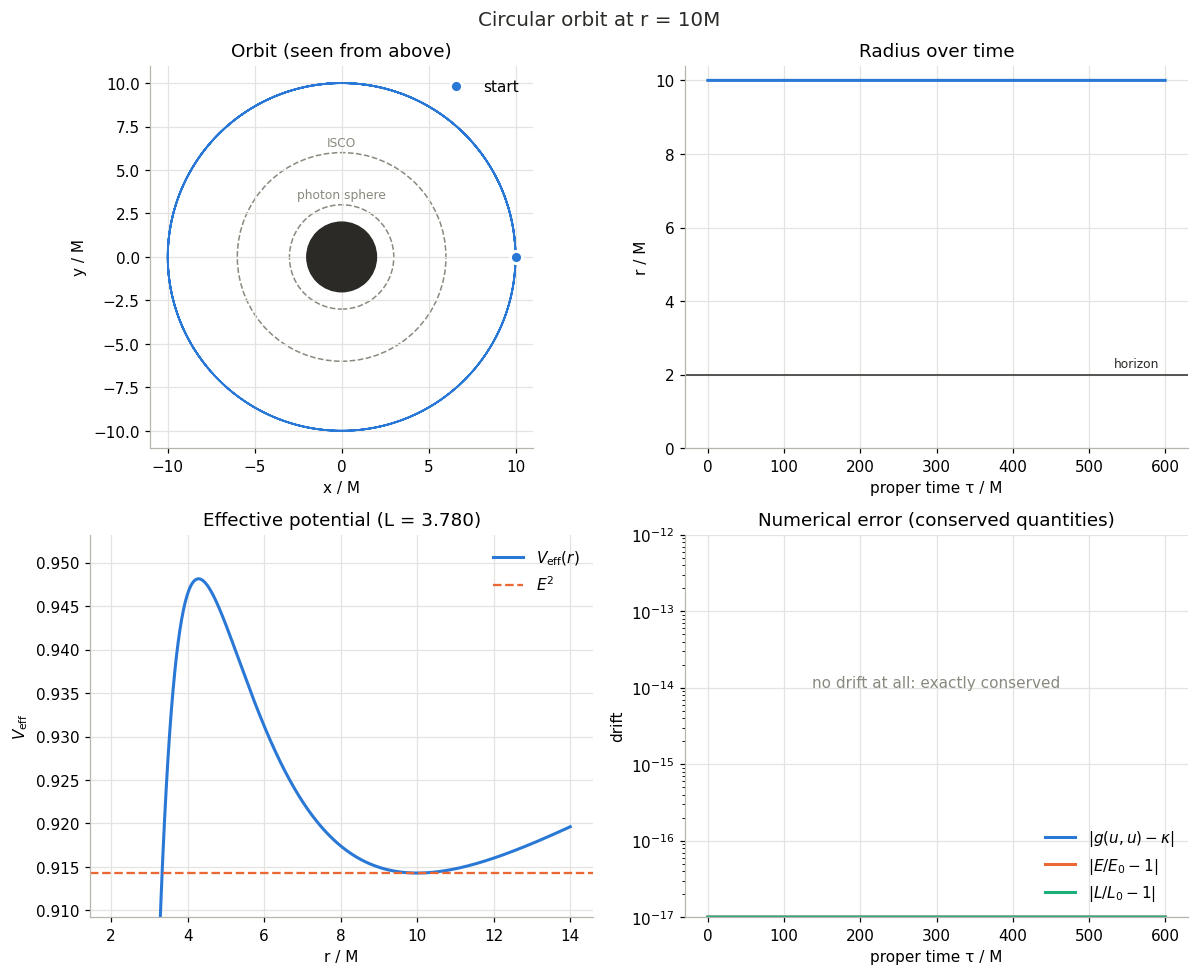

E = 0.956183,  L = 3.779645,  r between 10.000 and 10.000
max drift:  |g(u,u) - κ| = 0.0e+00,  E = 0.0e+00,  L = 0.0e+00


In [4]:
bh = Schwarzschild(M=1.0)
y0 = circular_orbit(bh, r=10.0)
taus, ys = run(bh, y0, tau_end=600, h=0.5)
plot_orbit(bh, taus, ys, title="Circular orbit at r = 10M")

## 2. Precessing (rosette) orbit

An eccentric bound orbit between $r = 10M$ and $r = 20M$. In Newtonian gravity it
would be a closed ellipse; in GR the periapsis advances on every orbit. The weak-field
formula $\Delta\phi \approx 6\pi M / p$ (with semi-latus rectum
$p = 2 r_p r_a / (r_p + r_a)$) is only a first approximation this close in, and
underestimates the true advance.

Integrated 16000 steps up to tau = 8000.


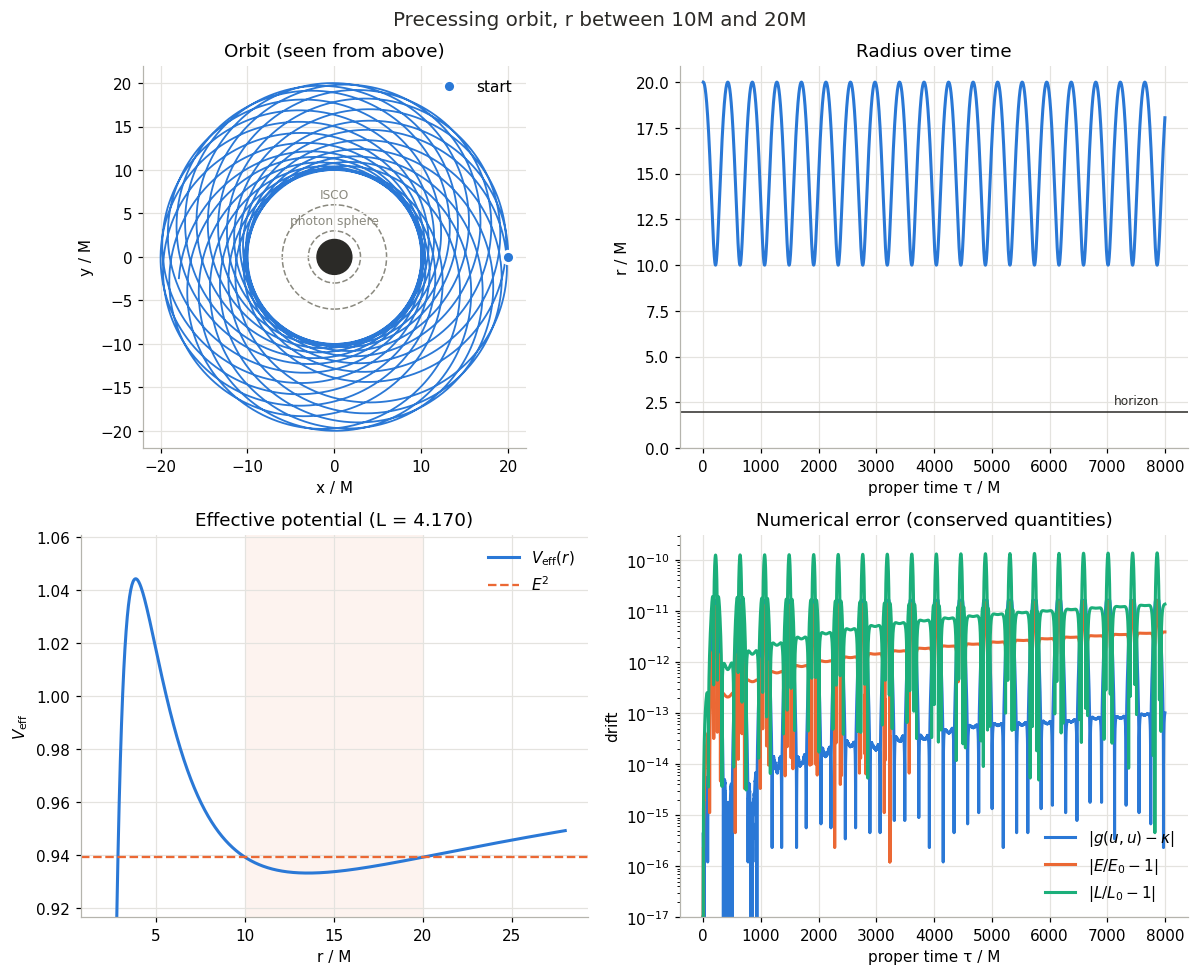

E = 0.969087,  L = 4.170288,  r between 10.000 and 20.000
max drift:  |g(u,u) - κ| = 1.7e-11,  E = 1.6e-11,  L = 1.4e-10
periapsis advance per orbit: 126.19°  (weak-field estimate 6πM/p = 81.00°)


In [5]:
y0 = bound_orbit(bh, r_peri=10.0, r_apo=20.0)
taus, ys = run(bh, y0, tau_end=8000, h=0.5)
plot_orbit(bh, taus, ys, title="Precessing orbit, r between 10M and 20M")

advance = periapsis_advance(ys)
rp, ra = ys[:, 1].min(), ys[:, 1].max()
p = 2 * rp * ra / (rp + ra)
print(f"periapsis advance per orbit: {np.degrees(advance.mean()):.2f}°  "
      f"(weak-field estimate 6πM/p = {np.degrees(6 * np.pi / p):.2f}°)")

## 3. Zoom-whirl orbit

If $E^2$ lies just below the top of the potential barrier, the particle "zooms" out,
falls back and "whirls" around the black hole several times near the unstable
circular orbit before zooming out again. Here $L = 3.8$ and $E^2$ is $10^{-5}$ below
the barrier maximum. Make the gap smaller for more whirls.

Integrated 12000 steps up to tau = 6000.


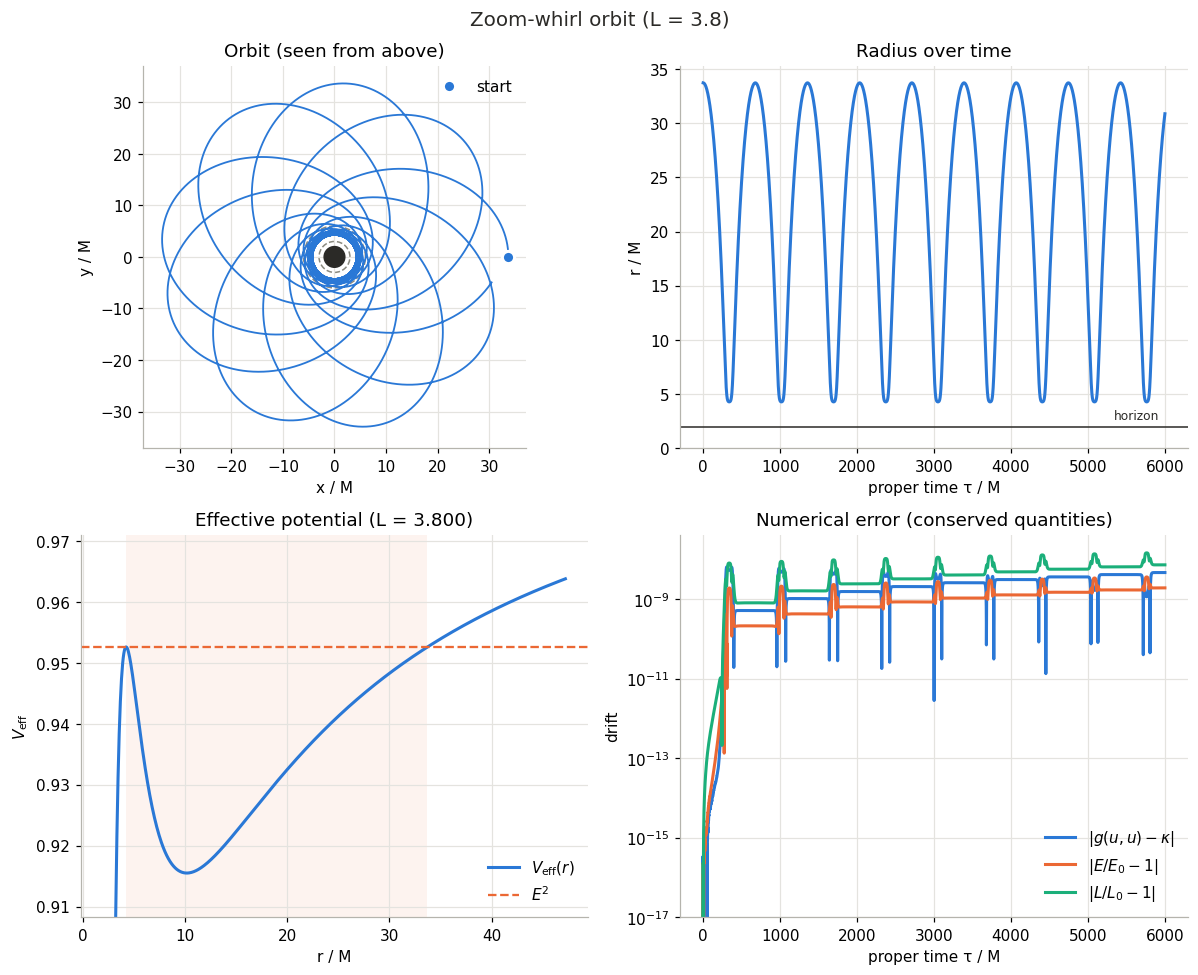

E = 0.976032,  L = 3.800000,  r between 4.275 and 33.724
max drift:  |g(u,u) - κ| = 6.4e-09,  E = 3.6e-09,  L = 1.4e-08
angle swept between periapses: 3.56 turns


In [6]:
L_zw = 3.8
rr = np.linspace(3.0, 10.0, 200_001)
V_max = np.max((1 - 2 / rr) * (1 + L_zw**2 / rr**2))       # top of the barrier
y0 = orbit_from_E_L(bh, E=np.sqrt(V_max * (1 - 1e-5)), L=L_zw)
taus, ys = run(bh, y0, tau_end=6000, h=0.5)
plot_orbit(bh, taus, ys, title="Zoom-whirl orbit (L = 3.8)")

turns = (periapsis_advance(ys) + 2 * np.pi) / (2 * np.pi)
print(f"angle swept between periapses: {turns.mean():.2f} turns")

## 4. Plunge

With too little angular momentum there is no barrier at all, and the particle spirals
into the black hole. For Schwarzschild every orbit with $L < \sqrt{12}\,M \approx 3.46M$
plunges. Here the particle starts at $r = 10M$ moving sideways with $L \approx 3.2$.

The drift panel shoots up at the end: not because the physics breaks, but because
$t$ and $u^t$ diverge at the horizon in these coordinates, which the step size
cannot follow. A smaller `h` pushes this closer to $r = 2M$.

Stopped at tau = 67.2: the particle reached the horizon (r = 2.00).


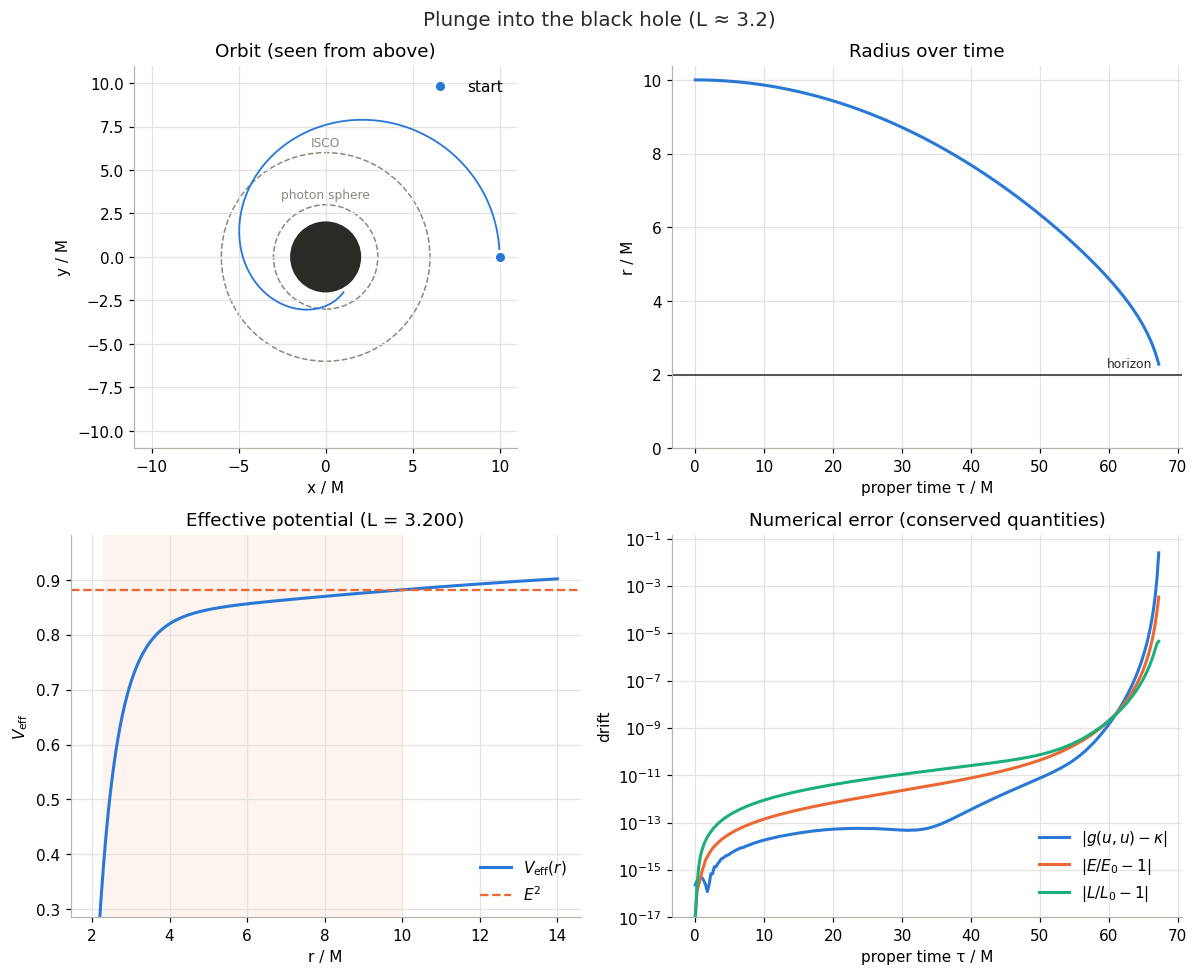

E = 0.939106,  L = 3.200000,  r between 2.281 and 10.000
max drift:  |g(u,u) - κ| = 2.5e-02,  E = 3.4e-04,  L = 4.5e-06


In [7]:
y0 = initial_state(bh, r0=10.0, uphi=3.2 / 10.0**2)
taus, ys = run(bh, y0, tau_end=500, h=0.25)
plot_orbit(bh, taus, ys, title="Plunge into the black hole (L ≈ 3.2)")

## 5. Light rays

Light rays ($\kappa = 0$) coming in from far away with different impact parameters $b$.
Rays with $b < 3\sqrt{3}\,M \approx 5.196M$ are captured, larger $b$ are deflected.
Rays just above the critical value circle the photon sphere $r = 3M$ before escaping.

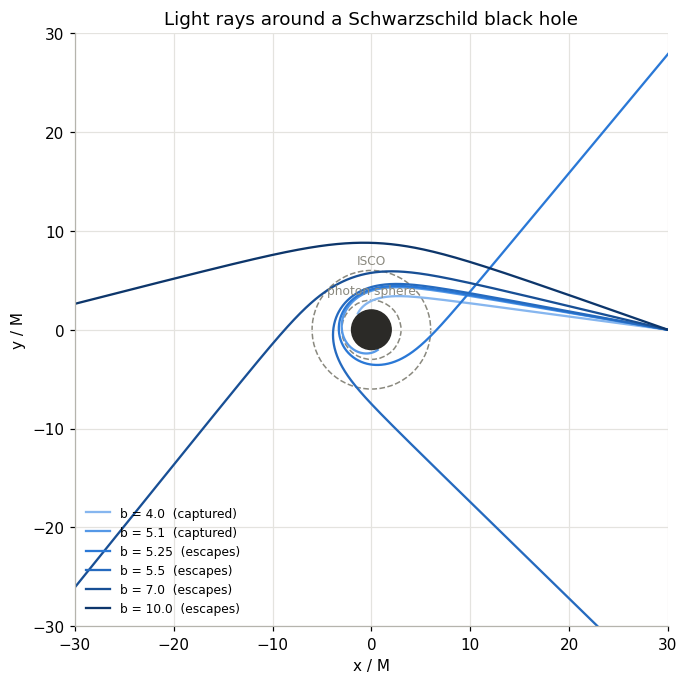

In [8]:
impact_parameters = [4.0, 5.1, 5.25, 5.5, 7.0, 10.0]
colors = ["#86b6ef", "#5598e7", "#2a78d6", "#256abf", "#184f95", "#0d366b"]   # light -> dark = small -> large b

fig, ax = plt.subplots(figsize=(7, 7))
for b, color in zip(impact_parameters, colors):
    taus, ys = run(bh, photon(bh, b=b, r0=30.0), tau_end=120, h=0.05, verbose=False)
    x, y, _ = cartesian(bh, ys)
    status = "captured" if ys[-1, 1] < 3 else "escapes"
    ax.plot(x, y, color=color, lw=1.5, label=f"b = {b}  ({status})")
draw_black_hole(ax, bh)
ax.set(xlim=(-30, 30), ylim=(-30, 30), aspect="equal", xlabel="x / M", ylabel="y / M",
       title="Light rays around a Schwarzschild black hole")
ax.legend(loc="lower left", fontsize=8)
plt.show()

## 6. Kerr: an inclined orbit around a spinning black hole

Kerr ($a = 0.9$) is not spherically symmetric, so an orbit that is tilted with respect
to the equator does not stay in one plane: frame dragging makes the orbital plane
precess (Lense-Thirring). Building the Kerr metric takes a couple of seconds, since its
Christoffel symbols are derived symbolically.

Integrated 3000 steps up to tau = 1500.


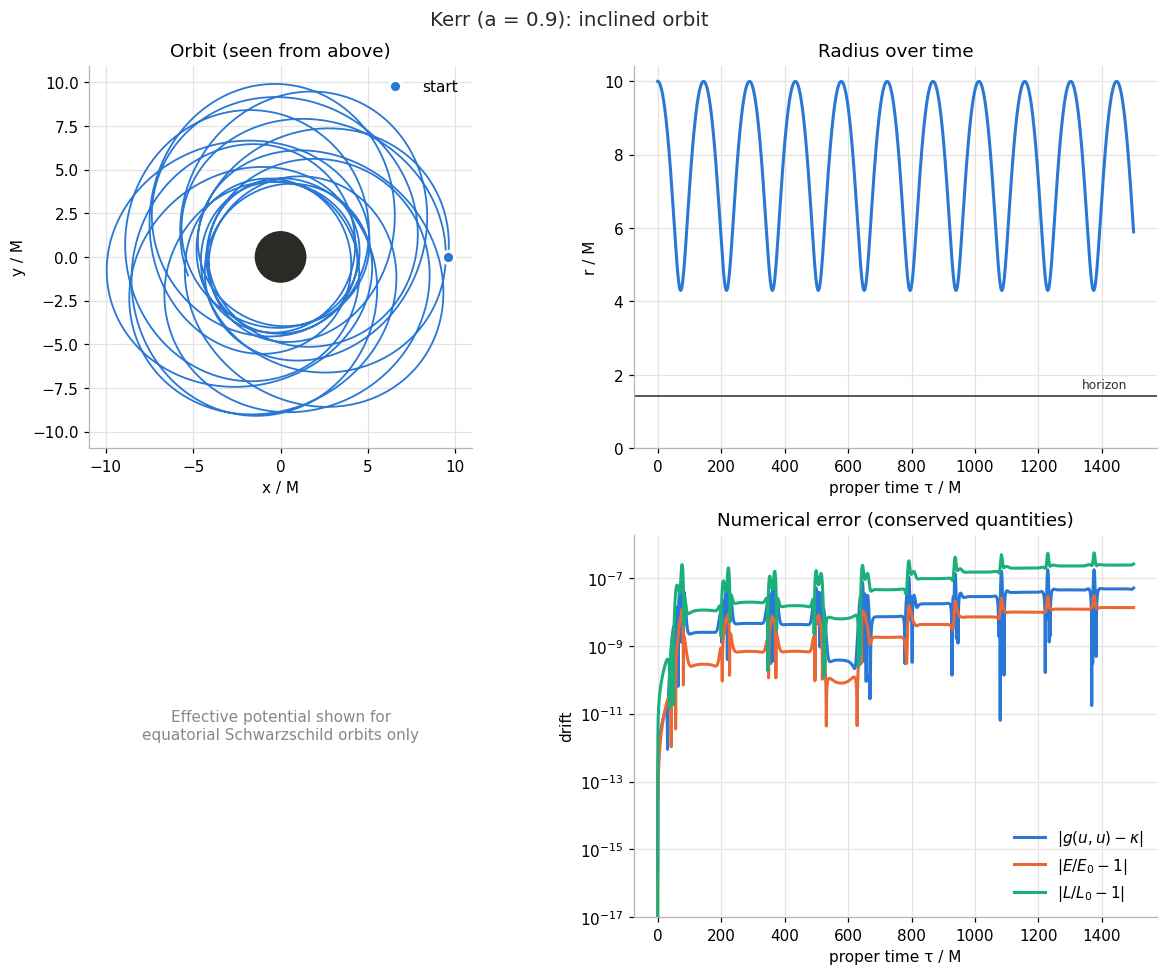

E = 0.935161,  L = 2.573371,  r between 4.301 and 10.000
max drift:  |g(u,u) - κ| = 1.8e-07,  E = 3.0e-08,  L = 5.6e-07


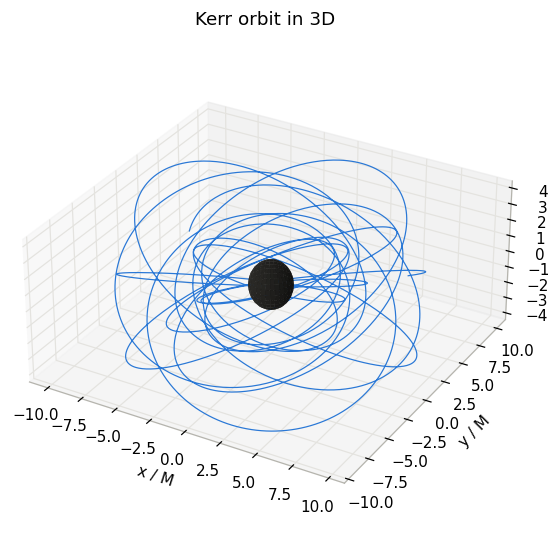

In [9]:
kerr = Kerr(M=1.0, a=0.9)
y0 = initial_state(kerr, r0=10.0, theta0=np.pi / 2 - 0.3, utheta=0.01, uphi=0.03)
taus, ys = run(kerr, y0, tau_end=1500, h=0.5)
plot_orbit(kerr, taus, ys, title="Kerr (a = 0.9): inclined orbit")

x, y, z = cartesian(kerr, ys)
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
ax.plot(x, y, z, color=BLUE, lw=0.8)
u, v = np.mgrid[0:2 * np.pi:30j, 0:np.pi:15j]
rh = horizon(kerr)
ax.plot_surface(rh * np.cos(u) * np.sin(v), rh * np.sin(u) * np.sin(v), rh * np.cos(v), color=INK)
zmax = max(np.abs(z).max(), rh)
ax.set(xlabel="x / M", ylabel="y / M", zlabel="z / M", zlim=(-zmax, zmax), title="Kerr orbit in 3D")
ax.set_box_aspect((np.ptp(x), np.ptp(y), 2 * zmax))     # same scale on all axes
plt.show()

## Other Orbits

Change the numbers and run the cell. Some ideas:

- `bound_orbit(bh, r_peri=..., r_apo=...)`: how does the precession change as $r_p$ approaches $6M$?
- `circular_orbit(bh, r=5.0)`: an unstable circular orbit. How long does it survive?
  Does a smaller step `h` keep it alive longer?
- `photon(bh, b=5.197)`: right at the critical impact parameter.
- `initial_state(...)` with `ur`, `utheta`, `uphi` of your choice, in `Schwarzschild` or `Kerr`
  (try `a = 0.99`, or a negative `uphi` for a retrograde orbit).
- Increase `h` and watch the drift panel: the error grows roughly like $h^4$.

Integrated 10000 steps up to tau = 5000.


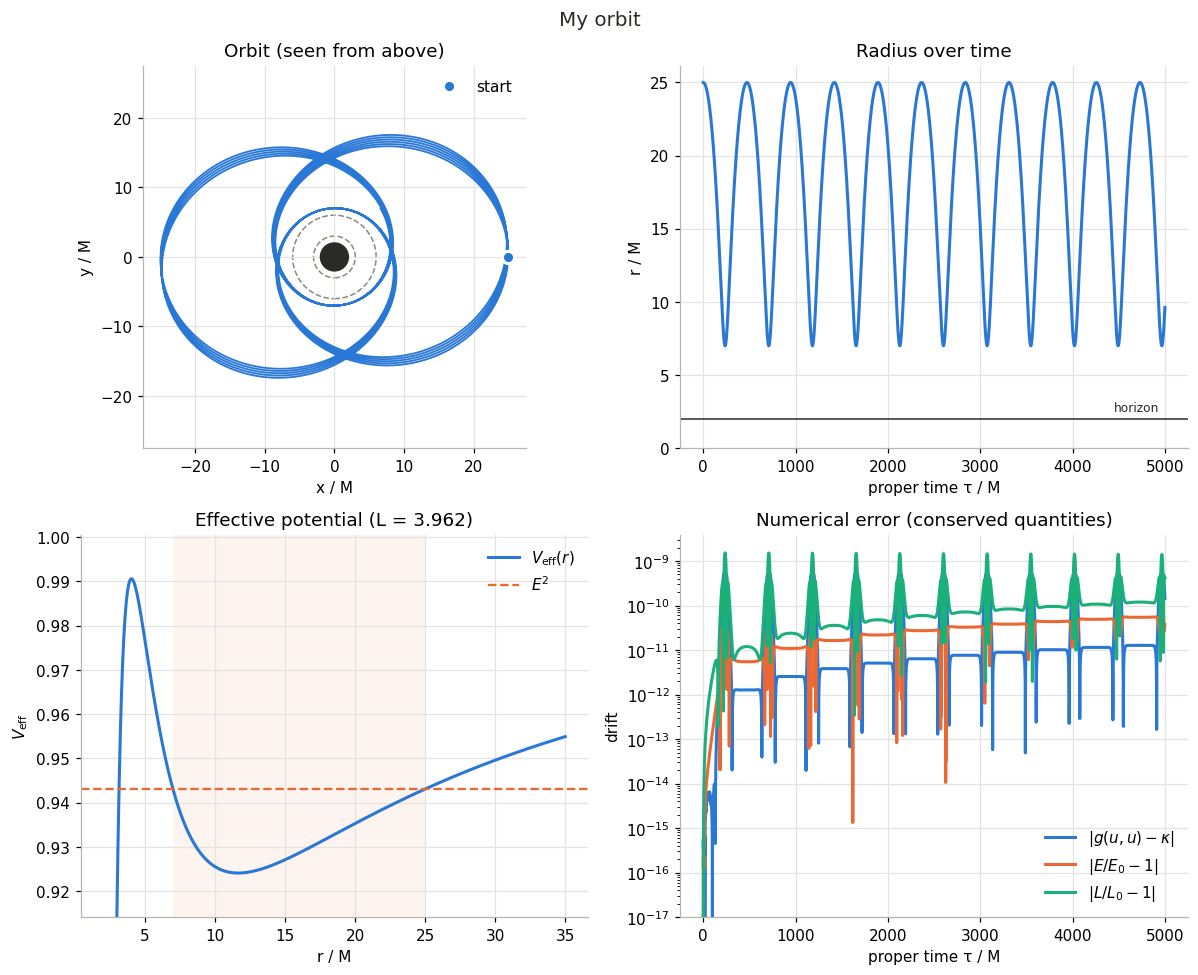

E = 0.971136,  L = 3.961954,  r between 7.000 and 25.000
max drift:  |g(u,u) - κ| = 5.2e-10,  E = 3.4e-10,  L = 1.5e-09


In [14]:
metric = Schwarzschild(M=1.0)          # or Kerr(M=1.0, a=0.9)

y0 = bound_orbit(metric, r_peri=7.0, r_apo=25.0)

kappa = -1                              # -1 for a massive particle, 0 for light
taus, ys = run(metric, y0, tau_end=5000, h=0.5)
plot_orbit(metric, taus, ys, kappa=kappa, title="My orbit")

Integrated 10000 steps up to tau = 5000.


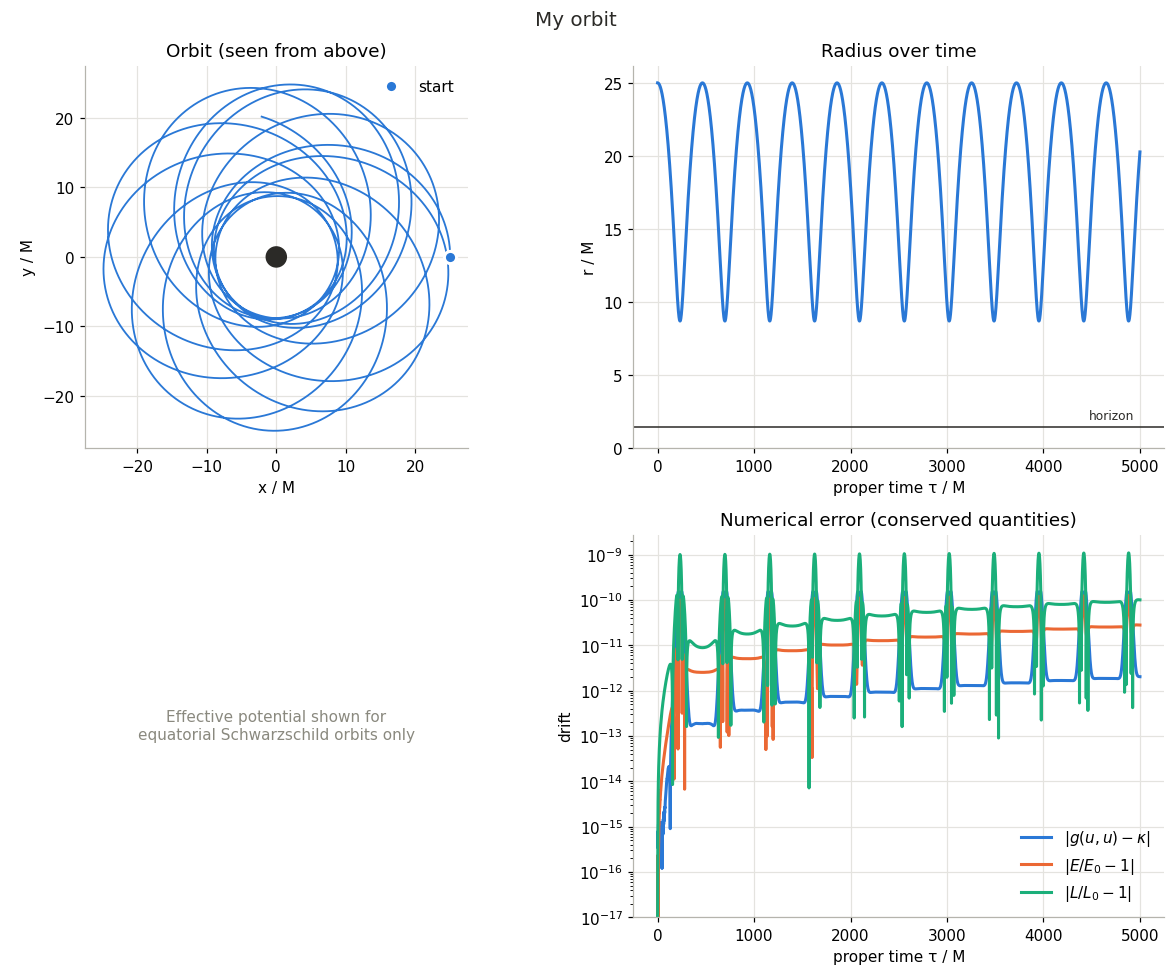

E = 0.971153,  L = 3.891532,  r between 8.701 and 25.000
max drift:  |g(u,u) - κ| = 1.6e-10,  E = 1.2e-10,  L = 1.1e-09


In [ ]:
metric = Kerr(M=1.0, a=0.9)

y0 = bound_orbit(metric, r_peri=7.0, r_apo=25.0)

kappa = -1                              # -1 for a massive particle, 0 for light
taus, ys = run(metric, y0, tau_end=5000, h=0.5)
plot_orbit(metric, taus, ys, kappa=kappa, title="My orbit")

Stopped at tau = 710.5: the particle reached the horizon (r = 2.00).


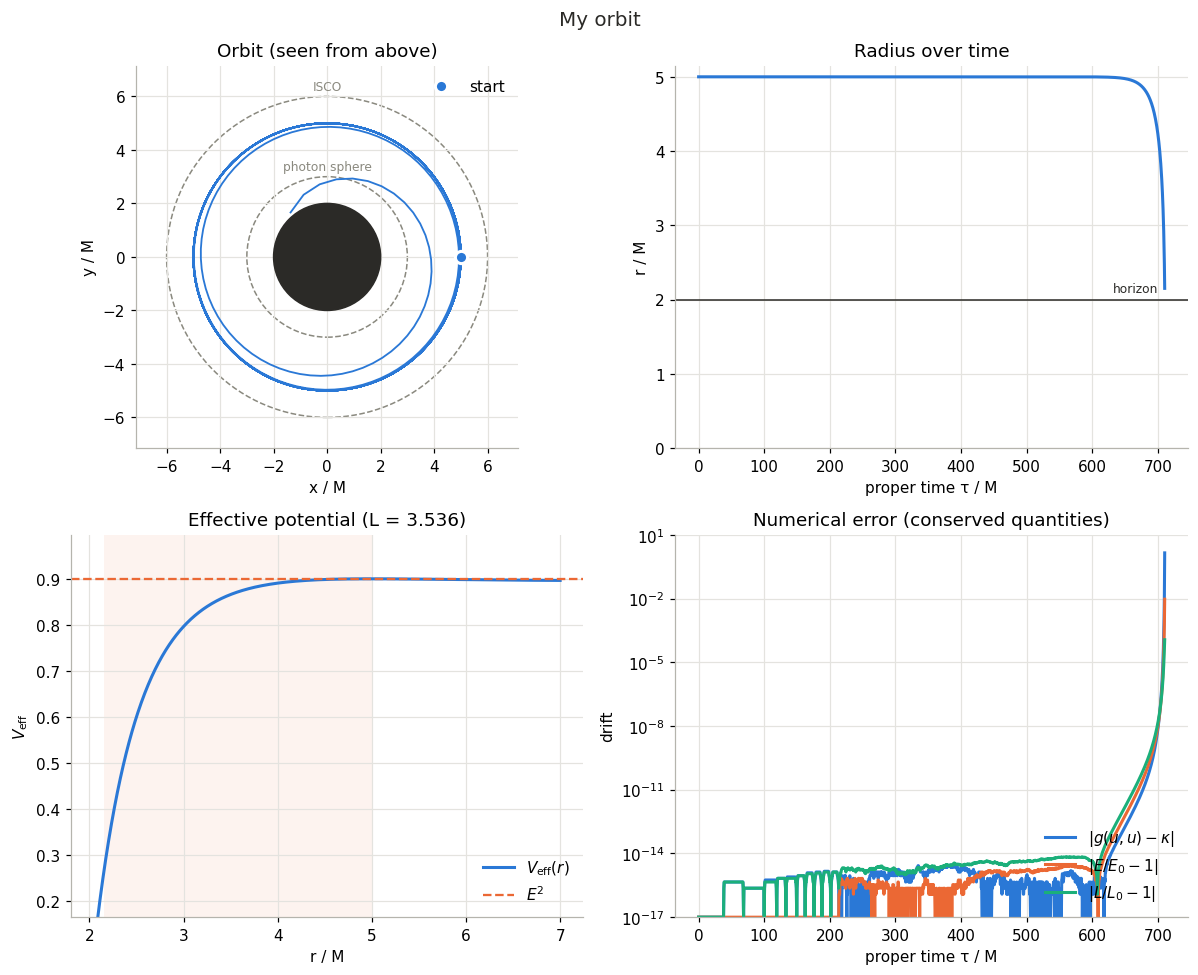

E = 0.948683,  L = 3.535534,  r between 2.152 and 5.000
max drift:  |g(u,u) - κ| = 1.4e+00,  E = 9.5e-03,  L = 1.2e-04


In [15]:
metric = Schwarzschild(M=1.0)          # or Kerr(M=1.0, a=0.9)

y0 = circular_orbit(metric, r=5.0)

kappa = -1                              # -1 for a massive particle, 0 for light
taus, ys = run(metric, y0, tau_end=5000, h=0.5)
plot_orbit(metric, taus, ys, kappa=kappa, title="My orbit")

Integrated 10000 steps up to tau = 5000.


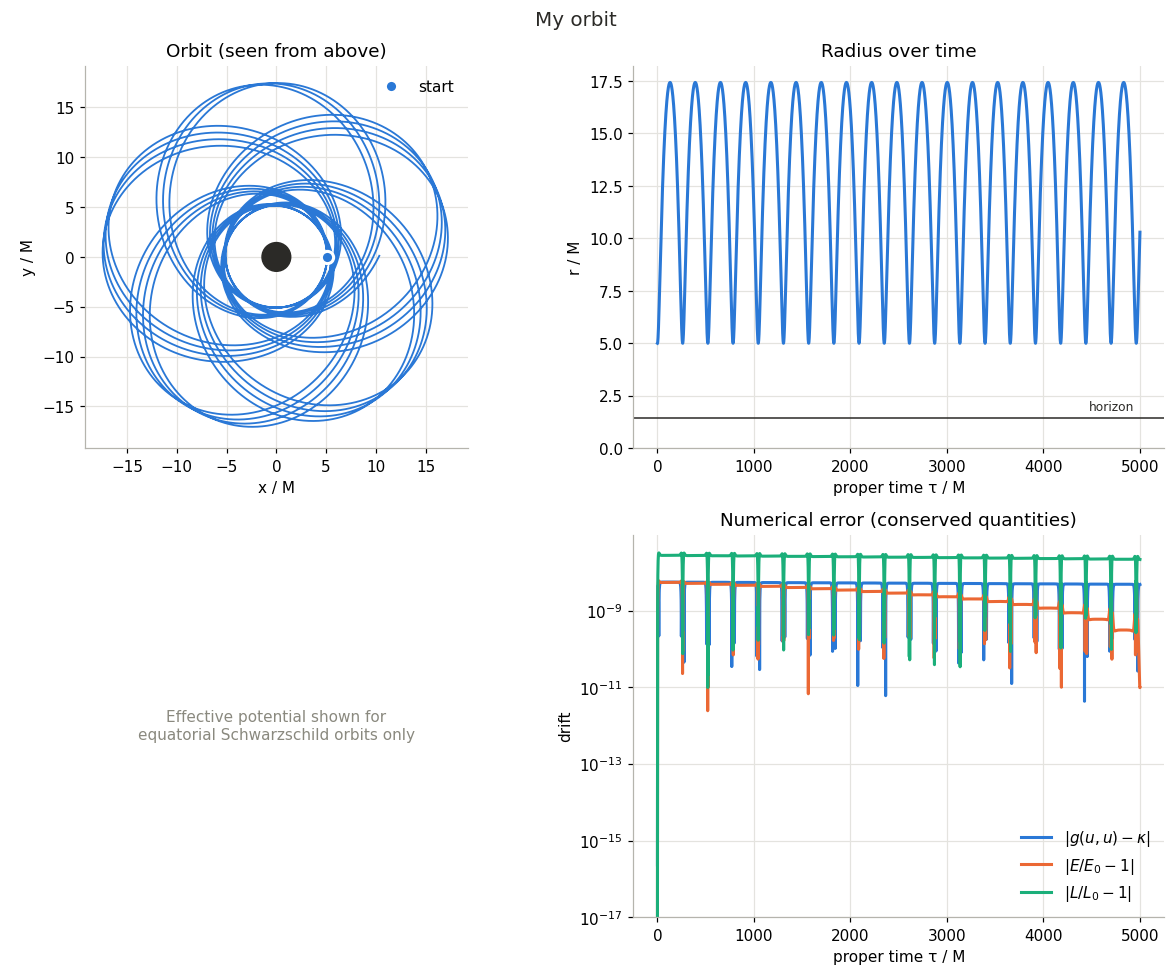

E = 0.957183,  L = 3.152143,  r between 5.000 and 17.429
max drift:  |g(u,u) - κ| = 5.6e-09,  E = 6.0e-09,  L = 3.2e-08


In [ ]:
metric = Kerr(M=1.0, a=0.9)

y0 = circular_orbit(metric, r=5.0)

kappa = -1                              # -1 for a massive particle, 0 for light
taus, ys = run(metric, y0, tau_end=5000, h=0.5)
plot_orbit(metric, taus, ys, kappa=kappa, title="My orbit")

Integrated 200 steps up to tau = 100.


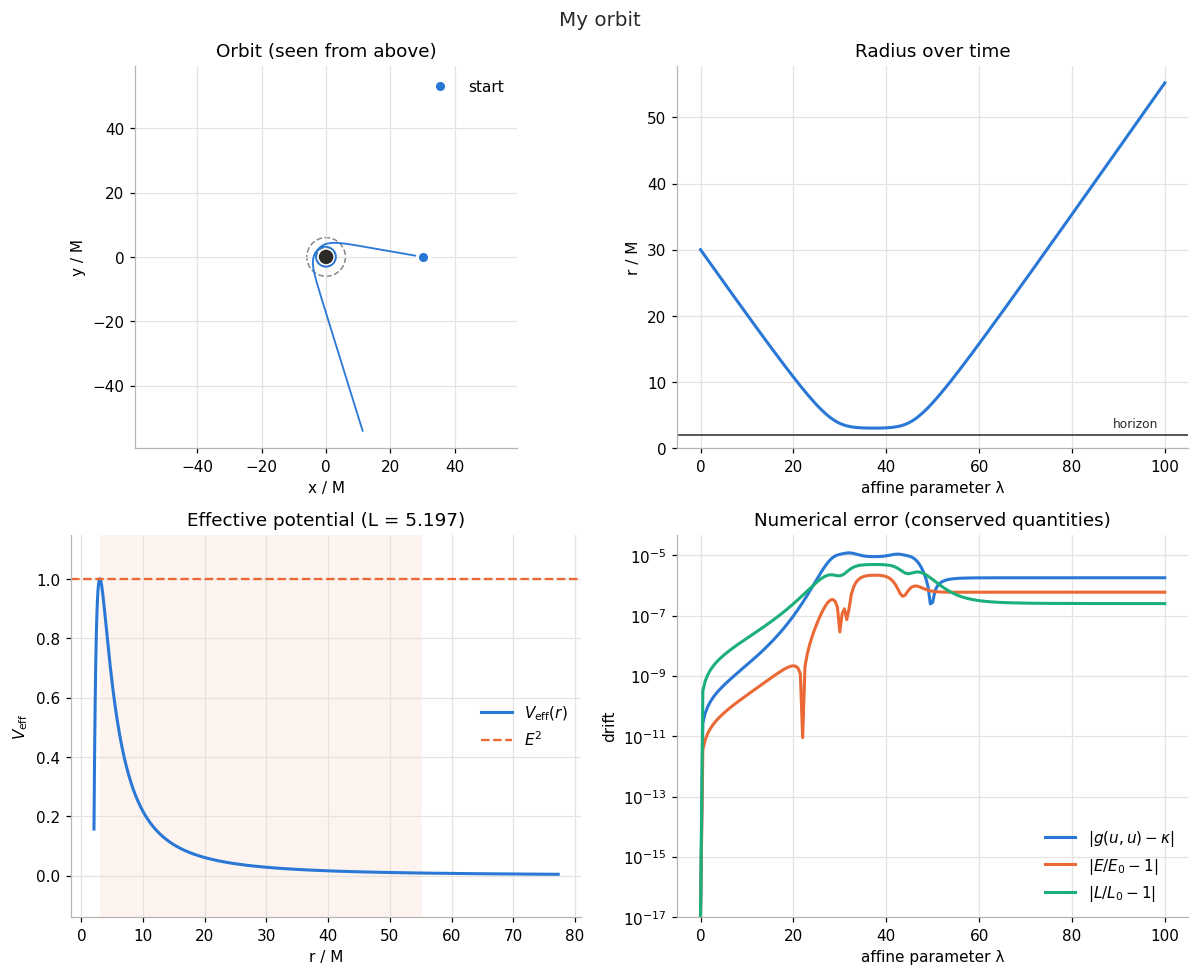

E = 1.000000,  L = 5.197000,  r between 3.032 and 55.201
max drift:  |g(u,u) - κ| = 1.2e-05,  E = 2.2e-06,  L = 4.9e-06


In [22]:
metric = Schwarzschild(M=1.0)          # or Kerr(M=1.0, a=0.9)

y0 = photon(metric, b=5.197, r0=30.0)

kappa = 0                            # -1 for a massive particle, 0 for light
taus, ys = run(metric, y0, tau_end=100, h=0.5)
plot_orbit(metric, taus, ys, kappa=kappa, title="My orbit")

Integrated 200 steps up to tau = 100.


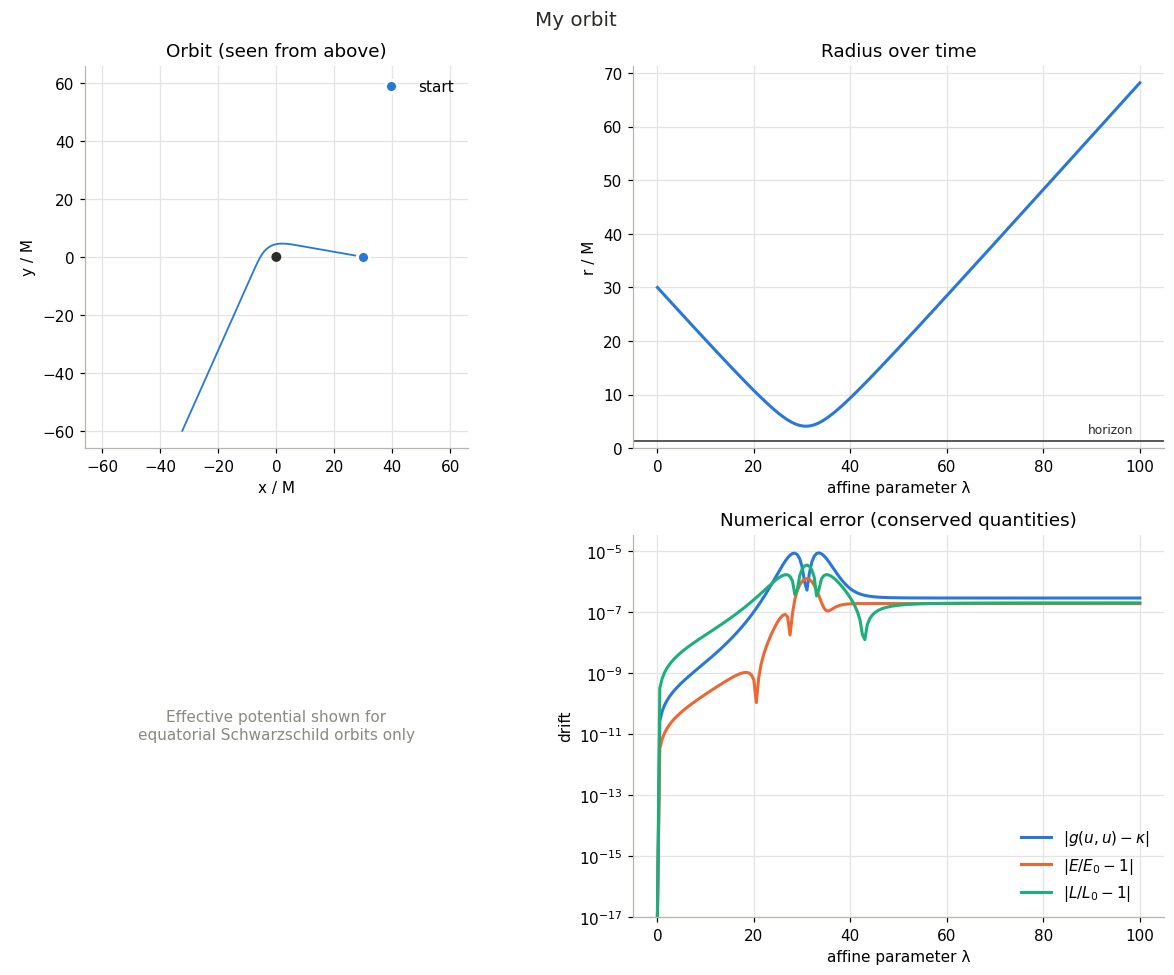

E = 0.999545,  L = 5.137755,  r between 4.109 and 68.190
max drift:  |g(u,u) - κ| = 8.9e-06,  E = 1.3e-06,  L = 3.5e-06


In [ ]:
metric = Kerr(M=1.0, a=0.9)

y0 = photon(metric, b=5.197, r0=30.0)

kappa = 0                            # -1 for a massive particle, 0 for light
taus, ys = run(metric, y0, tau_end=100, h=0.5)
plot_orbit(metric, taus, ys, kappa=kappa, title="My orbit")

Stopped at tau = 89.5: the particle reached the horizon (r = 2.00).


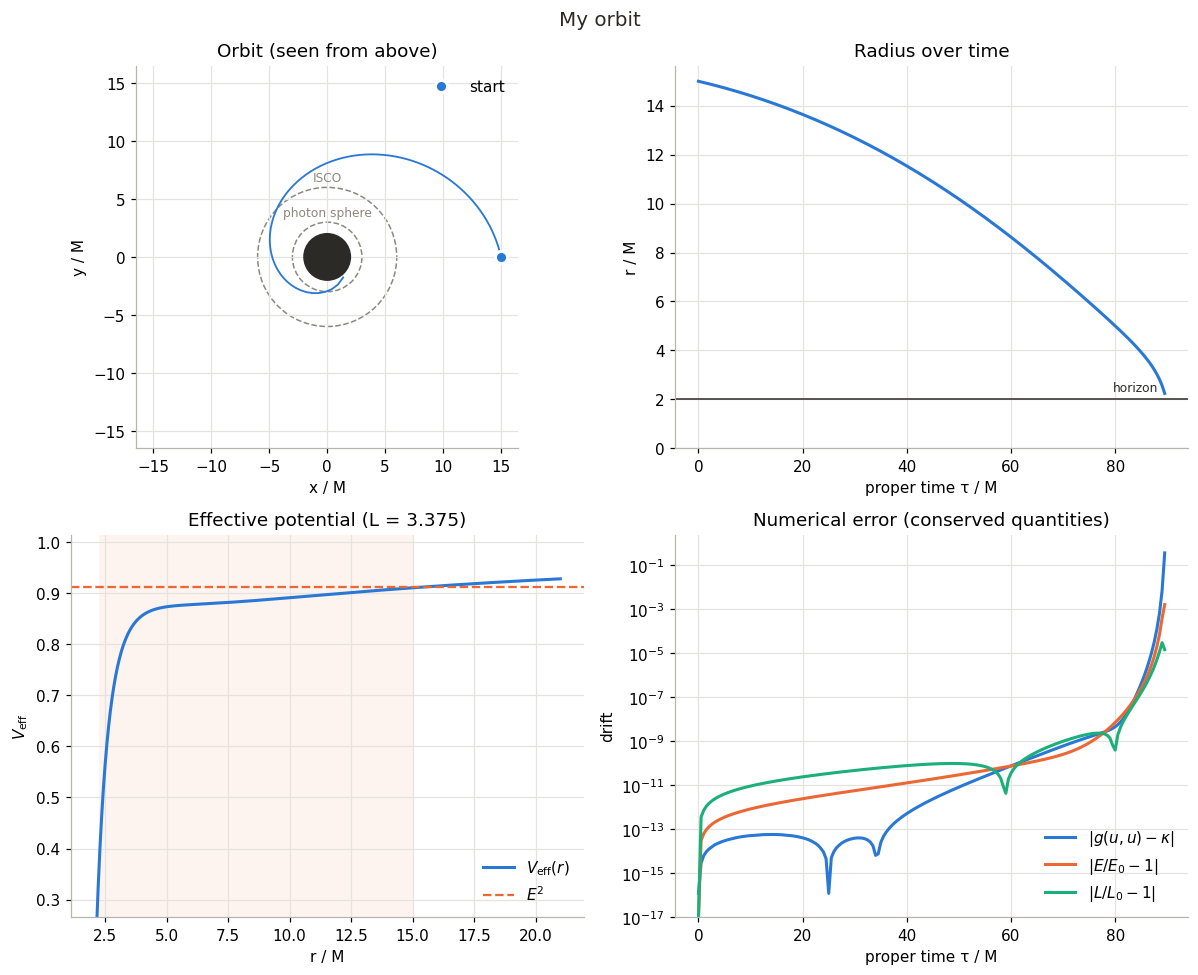

E = 0.955532,  L = 3.375000,  r between 2.241 and 15.000
max drift:  |g(u,u) - κ| = 3.6e-01,  E = 1.6e-03,  L = 3.0e-05


In [17]:
metric = Schwarzschild(M=1.0)          # or Kerr(M=1.0, a=0.9)

y0 = initial_state(metric, r0=15.0, ur=-0.05, uphi=0.015)

kappa = -1                              # -1 for a massive particle, 0 for light
taus, ys = run(metric, y0, tau_end=5000, h=0.5)
plot_orbit(metric, taus, ys, kappa=kappa, title="My orbit")

Integrated 10000 steps up to tau = 5000.


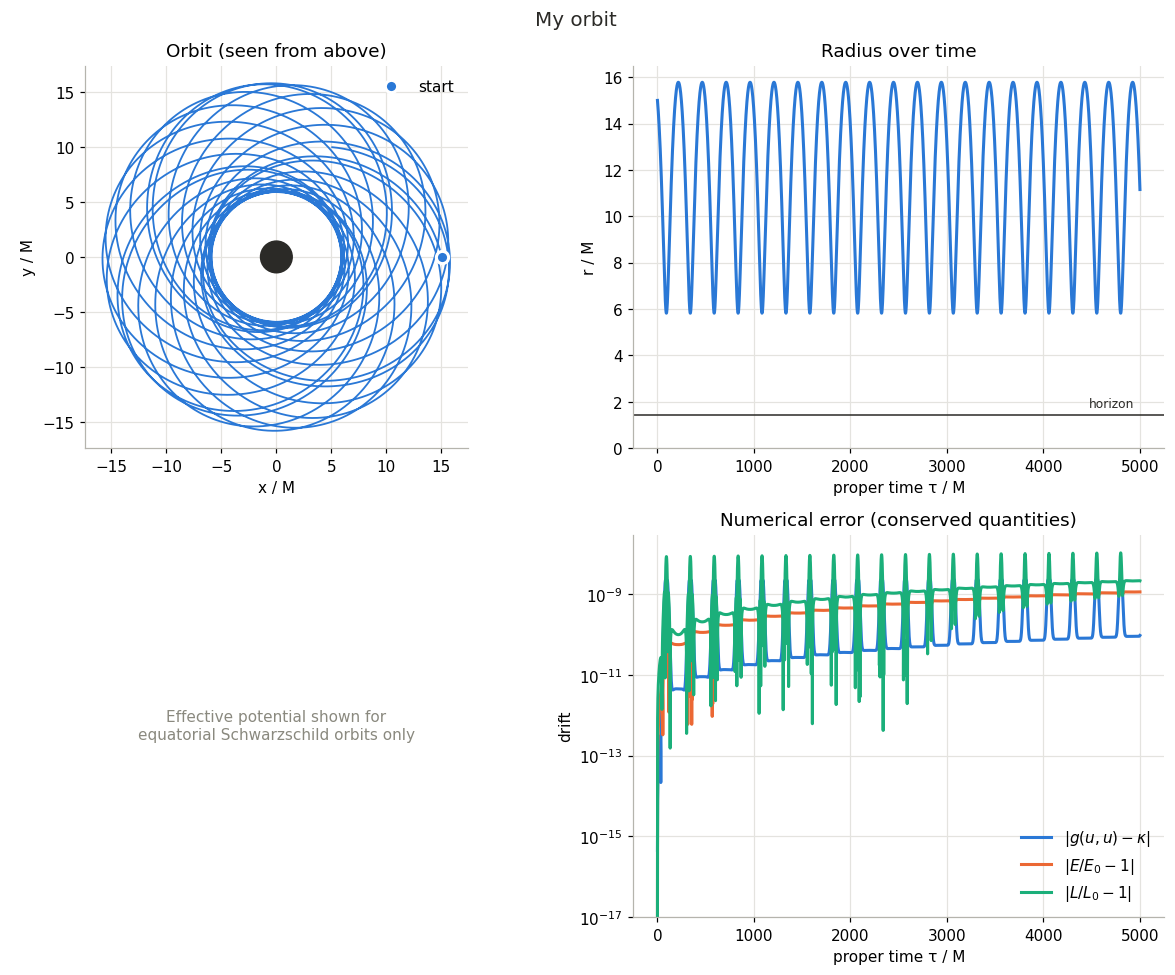

E = 0.955622,  L = 3.256702,  r between 5.823 and 15.781
max drift:  |g(u,u) - κ| = 2.3e-09,  E = 2.5e-09,  L = 1.1e-08


In [33]:
metric = Kerr(M=1.0, a=0.9)

y0 = initial_state(metric, r0=15, ur=-0.05, uphi=0.015)

kappa = -1                              # -1 for a massive particle, 0 for light
taus, ys = run(metric, y0, tau_end=5000, h=0.5)
plot_orbit(metric, taus, ys, kappa=kappa, title="My orbit")